# Figure 3

Relationship between pattern similarity and memory-guided search behavior (session 2). Reads .nii.gz files produced by `precompute/glm_scene_nii.py`. Produces `dataframes/pattern_sim_avg.csv` and `dataframes/pattern_sim_behav_data.csv`, read by `supp_figure3.ipynb` and `supp_figure4.ipynb`.

In [1]:
import os.path as op

import numpy as np
import pandas as pd
import nibabel as nib
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

from mgvs_release import config
from mgvs_release.behavior import prepare_sacc_both
from mgvs_release.plotting import setup_style, plot_rank_bin_effect, save_fig
from mgvs_release.rois import load_roi_masks
from mgvs_release.stats import paired_ttest

In [2]:
setup_style()

In [3]:
bids_dir = config.BIDS_DIR
deriv_dir = config.DERIV_DIR
subjects = config.SUBJECTS

rois = ['V1_V3', 'hipp', 'hipp_anterior', 'hipp_posterior', 'CoS-places', 'phc', 'rsc', 'DAN']
N_SCENE_PAIRS = 12  # unique scene categories

save_dir = '../plots/'
dataframes_dir = '../dataframes/'

## Load behavioral data

In [4]:
stim_info = []
for sub in subjects:
    s = pd.read_csv(
        op.join(deriv_dir, 'behavioral-prep', sub, f'{sub}_cond_info.csv')
    ).set_index('stim_name')
    s = s.assign(subject=sub)
    stim_info.append(s)
stim_info = pd.concat(stim_info)

In [5]:
sacc_both = prepare_sacc_both(bids_dir, dataframes_dir, subjects,
                               roll_cols=['targ_resp', 'comp_resp', 'sacc_targ_err'],
                               strict_err_thresh=10)

In [6]:
search_cat_perf = sacc_both.query(
    "cue_validity=='valid' & trial!=56"
).groupby(['subject', 'stim_category', 'sacc_type']).mean(numeric_only=True).reset_index()
search_cat_perf['subj'] = search_cat_perf['subject']

## Load ROI masks

In [7]:
roi_masks = load_roi_masks(deriv_dir, subjects, rois)

## Pattern similarity (+ univariate) computation

In [8]:
ps_df = []
univ_df = []
for subj in subjects:
    sinfo = stim_info.query("subject==@subj")
    # precompute/glm_scene_nii.py saves "castle-alt" under the sanitized 
    # filename "castlealt.nii.gz"
    sinfo = sinfo.rename(index={'castle-alt': 'castlealt'})

    betas_dir = op.join(deriv_dir, 'glm-scene_nii', subj, 'ses-01')
    betas = {stim: nib.load(op.join(betas_dir, stim + '.nii.gz')).get_fdata()
             for stim in sinfo.index.values}

    for r in rois:
        roi_mask = roi_masks[subj][r]
        roi_betas = np.vstack([betas[stim][roi_mask] for stim in sinfo.index.values])

        # Univariate: mean beta per stimulus, within this ROI.
        univ_df.append(pd.DataFrame(dict(stim_name=sinfo.index.values, roi=r,
                                          mean_beta=roi_betas.mean(axis=1), subj=subj)))

        # Pattern similarity: pairwise stimulus correlation, within this ROI.
        corr = pd.DataFrame(roi_betas.T).corr(method='pearson')
        corr.index = pd.Index(sinfo.index.values, name='stim1_name')
        corr.columns = pd.Index(sinfo.index.values, name='stim2_name')

        # Flatten and merge with stim info
        keep = np.triu(np.ones(corr.shape), 1).astype('bool').reshape(corr.shape)
        corr_df = corr.unstack().reset_index()[keep.flatten()]
        corr_df = corr_df.merge(sinfo[['next_target_ang', 'stim_category']],
                                 left_on='stim1_name', right_on='stim_name', how='outer')
        corr_df = corr_df.merge(sinfo[['next_target_ang', 'stim_category']],
                                 left_on='stim2_name', right_on='stim_name', how='outer',
                                 suffixes=('_1', '_2'))
        corr_df = corr_df.rename(columns={0: 'corr'})

        # Fisher z transform
        corr_df['corr_z'] = corr_df['corr'].apply(lambda x: .5 * (np.log(1+x) - np.log(1-x)))

        # Define within pair comparisons
        corr_df['within_pair'] = corr_df['stim_category_1'] == corr_df['stim_category_2']

        # Build df where each stim_category has its within-category pair plus 
        # every possible across-category pairing
        for c in corr_df['stim_category_1'].unique():
            isc = np.logical_or(corr_df['stim_category_1'] == c, corr_df['stim_category_2'] == c)
            cdf = corr_df[isc][['within_pair', 'corr', 'corr_z',
                                'stim1_name', 'stim2_name',
                                'next_target_ang_1', 'next_target_ang_2']].copy()
            cdf = cdf.assign(stim_category=c, roi=r, subj=subj)
            ps_df.append(cdf)

ps_df = pd.concat(ps_df).reset_index(drop=True)
univ_df = pd.concat(univ_df).reset_index(drop=True)

In [9]:
# Within verus across pair pattern similarity
within_mean = ps_df.query("within_pair==True").groupby(['subj', 'roi', 'stim_category'])['corr_z'].mean()
across_mean = ps_df.query("within_pair==False").groupby(['subj', 'roi', 'stim_category'])['corr_z'].mean()
ps_diff_df = (within_mean - across_mean).reset_index()

In [10]:
univ_df = univ_df.pivot_table(index=['subj', 'stim_name'], values='mean_beta', columns=['roi']).reset_index()
# stim_category is fixed so reusing last subject `sinfo` is fine
univ_df['stim_category'] = sinfo.loc[univ_df['stim_name']]['stim_category'].values
univ_df = univ_df.groupby(['subj', 'stim_category']).mean(numeric_only=True).reset_index()

ps_diff_df = ps_diff_df.merge(univ_df, on=['subj', 'stim_category'])

## Fig 3B: EVC vs HIPP pattern similarity

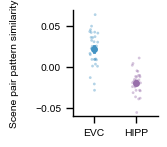

In [11]:
f, ax = plt.subplots(1, 1, figsize=(1.7, 1.5))
pal = ['#4393c3', '#9970ab']
ax = sns.pointplot(x='roi', y='corr_z', order=['V1_V3', 'hipp'], errorbar='se',
                   hue='roi', hue_order=['V1_V3', 'hipp'], markersize=3.5, linewidth=2,
                   palette=pal,
                   data=ps_diff_df.groupby(['subj', 'roi']).mean(numeric_only=True).reset_index())
sns.stripplot(x='roi', y='corr_z', order=['V1_V3', 'hipp'], hue_order=['V1_V3', 'hipp'], alpha=.4, s=2,
              hue='roi', palette=pal, zorder=-100,
              data=ps_diff_df.groupby(['subj', 'roi']).mean(numeric_only=True).reset_index(), ax=ax)
ax.set(xlabel='', xticks=range(2), xticklabels=['EVC', 'HIPP'], ylim=[-.06, .07], yticks=[-.05, 0, .05],
       ylabel='Scene pair pattern similarity\n')
ax.legend_ = None
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'fig3b'))

In [12]:
ps_diff_mean = ps_diff_df.groupby(['subj', 'roi']).mean(numeric_only=True).reset_index()

In [13]:
paired_ttest(ps_diff_mean.query("roi=='hipp'")['corr_z'], ps_diff_mean.query("roi=='V1_V3'")['corr_z'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-10.212708,31,two-sided,1.933981e-11,"[-0.05, -0.03]",2.332591,4.796e+08,1.0


In [14]:
# ps_diff_mean is also used by supp_figure4.ipynb 
ps_diff_mean.to_csv(op.join(dataframes_dir, 'pattern_sim_avg.csv'))

## Fig 3C: HIPP and EVC pattern similarity correlation with behavior

In [15]:
ps_diff_perf = ps_diff_df.merge(search_cat_perf, on=['subj', 'stim_category'])

In [16]:
ps_diff_perf['next_targ_err_center'] = (ps_diff_perf['next_sacc_targ_err'] -
    ps_diff_perf.groupby(['subj', 'roi', 'sacc_type'])['next_sacc_targ_err'].transform('mean'))

In [17]:
# corr_z_norm feeds the continuous version of the analysis in
# supp_figure3.ipynb
corr_z_group = ps_diff_perf.groupby(['subj', 'roi', 'sacc_type'])['corr_z']
ps_diff_perf['corr_z_norm'] = corr_z_group.transform(stats.zscore)

In [18]:
# ps_diff_perf_sorted is also used by supp_figure3.ipynb and supp_figure4.ipynb
ps_diff_perf_sorted = ps_diff_perf.groupby(['subj', 'roi', 'sacc_type']).apply(
    lambda x: x.sort_values(by='corr_z')).reset_index(drop=True)
ps_diff_perf_sorted['rank'] = np.tile(np.arange(1, N_SCENE_PAIRS + 1), len(subjects)*len(rois)*2)
# Median split: bottom half of ranks (lowest pattern similarity) -> bin 1, top half -> bin 2.
ps_diff_perf_sorted['rank_bin'] = np.where(ps_diff_perf_sorted['rank'] <= N_SCENE_PAIRS // 2, 1, 2)
ps_diff_perf_sorted.to_csv(op.join(dataframes_dir, 'pattern_sim_behav_data.csv'))

HIPP (right)

In [19]:
ps_diff_perf_sorted_hipp = ps_diff_perf_sorted.query("roi=='hipp' & sacc_type=='first'")
ps_diff_perf_sorted_hipp = ps_diff_perf_sorted_hipp.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

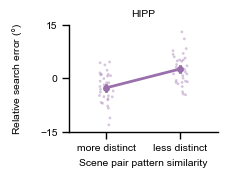

In [20]:
plot_rank_bin_effect(ps_diff_perf_sorted_hipp, y='next_targ_err_center', color='#9970ab', title='HIPP',
                      ylabel='Relative search error ($\degree$)\n', ylim=[-15, 15], yticks=[-15, 0, 15],
                      save_path=op.join(save_dir, 'fig3c_hipp.svg'))

In [21]:
# Smaller saccade errors for more distinct (lower pattern similarity) pairs vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_hipp.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_hipp.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-3.462223,31,two-sided,0.001585,"[-8.43, -2.18]",0.322884,21.683,0.424721


EVC (left)

In [22]:
ps_diff_perf_sorted_v1v3 = ps_diff_perf_sorted.query("roi=='V1_V3' & sacc_type=='first'")
ps_diff_perf_sorted_v1v3 = ps_diff_perf_sorted_v1v3.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

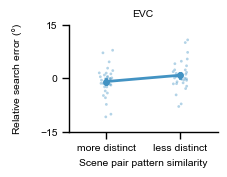

In [23]:
plot_rank_bin_effect(ps_diff_perf_sorted_v1v3, y='next_targ_err_center', color='#4393c3', title='EVC',
                      ylabel='Relative search error ($\degree$)\n', ylim=[-15, 15], yticks=[-15, 0, 15],
                      save_path=op.join(save_dir, 'fig3c_evc.svg'))

In [24]:
# No difference in saccade errors for more distinct (lower pattern similarity) vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_v1v3.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_v1v3.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-1.24384,31,two-sided,0.222882,"[-4.69, 1.14]",0.108576,0.382,0.091495


## Reported in text

In [25]:
# Alternative test to one reported above with stricter accuracy criteria
paired_ttest(ps_diff_perf_sorted_hipp.query("rank_bin==1")['next_targ_resp_strict'],
             ps_diff_perf_sorted_hipp.query("rank_bin==2")['next_targ_resp_strict'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,2.671629,31,two-sided,0.011921,"[0.0, 0.04]",0.311838,3.798,0.401189
